228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 105s 0us/step
Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


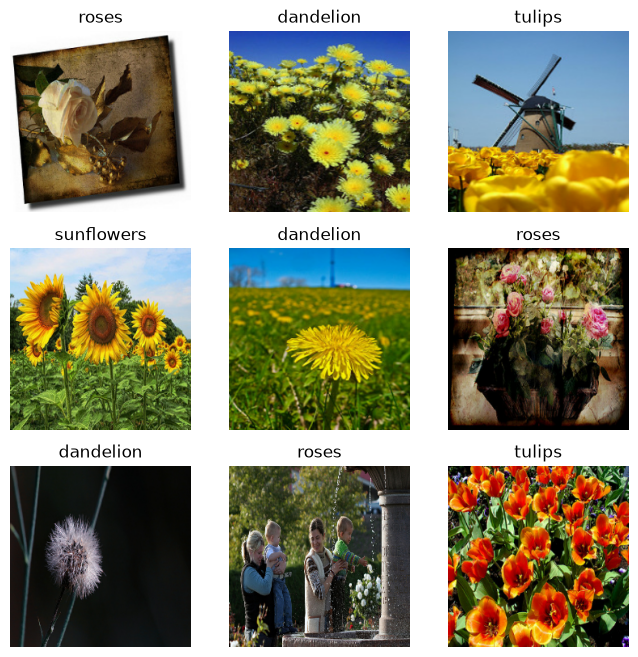

Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 54s 569ms/step - accuracy: 0.8007 - loss: 0.5445 - val_accuracy: 0.8828 - val_loss: 0.3442
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 51s 552ms/step - accuracy: 0.9254 - loss: 0.2276 - val_accuracy: 0.8937 - val_loss: 0.3215
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 51s 553ms/step - accuracy: 0.9530 - loss: 0.1503 - val_accuracy: 0.9114 - val_loss: 0.3036
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 983ms/step


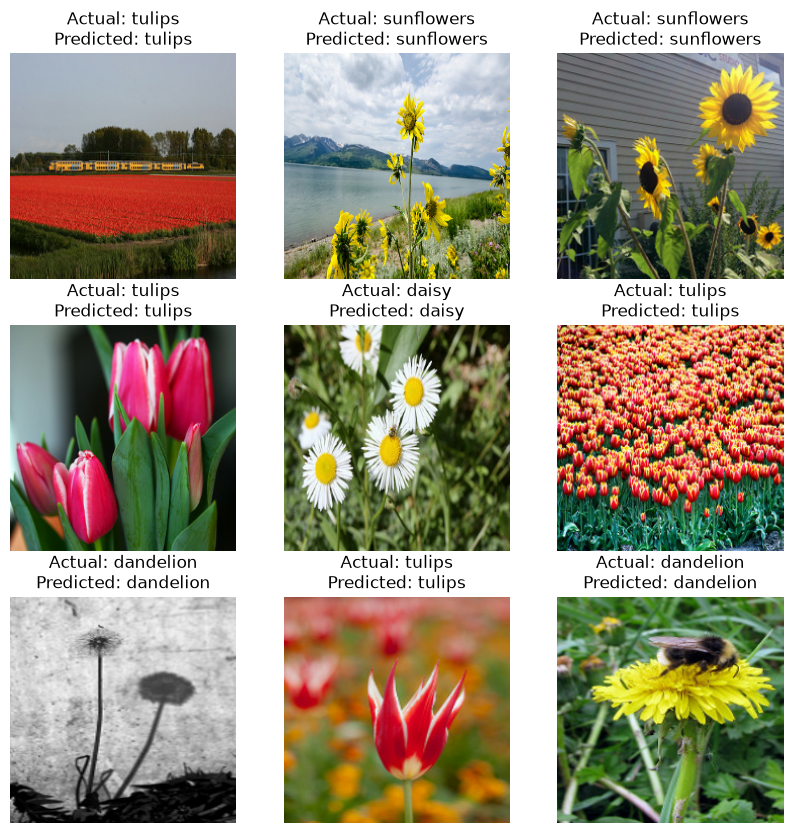

Predicted flower: tulips


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Download dataset
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file("flowers", url, untar=True) + "/flower_photos"

# Load dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training",
    seed=123, image_size=(224, 224), batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation",
    seed=123, image_size=(224, 224), batch_size=32
)

classes = train_ds.class_names
print("Classes:", classes)

# Display sample images
images, labels = next(iter(train_ds))

plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(classes[labels[i]])
    plt.axis("off")
plt.show()

# Preprocess images
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))

# Load MobileNetV2
base_model = MobileNetV2(
    weights="imagenet", include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

# Create model
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(5, activation="softmax")
])

# Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.fit(train_ds, validation_data=val_ds, epochs=3)

# Predict flowers
images, labels = next(iter(val_ds))
predictions = model.predict(images)
predicted_labels = np.argmax(predictions, axis=1)

# Display predicted images
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)

    img = ((images[i].numpy() + 1) * 127.5).astype("uint8")
    plt.imshow(img)

    plt.title("Actual: " + classes[labels[i]] +
              "\nPredicted: " + classes[predicted_labels[i]])
    plt.axis("off")
plt.show()

# Print one prediction
print("Predicted flower:", classes[predicted_labels[0]])

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


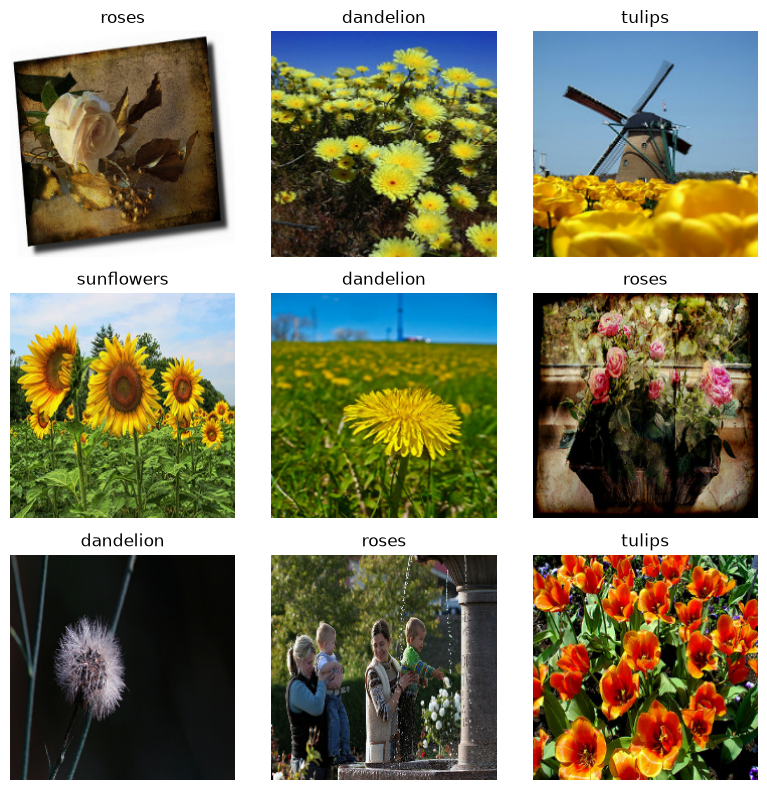

Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 58s 608ms/step - accuracy: 0.8137 - loss: 0.5259 - val_accuracy: 0.8896 - val_loss: 0.3379
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 52s 566ms/step - accuracy: 0.9247 - loss: 0.2267 - val_accuracy: 0.8924 - val_loss: 0.3161
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 49s 534ms/step - accuracy: 0.9581 - loss: 0.1390 - val_accuracy: 0.8978 - val_loss: 0.3046
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 960ms/step


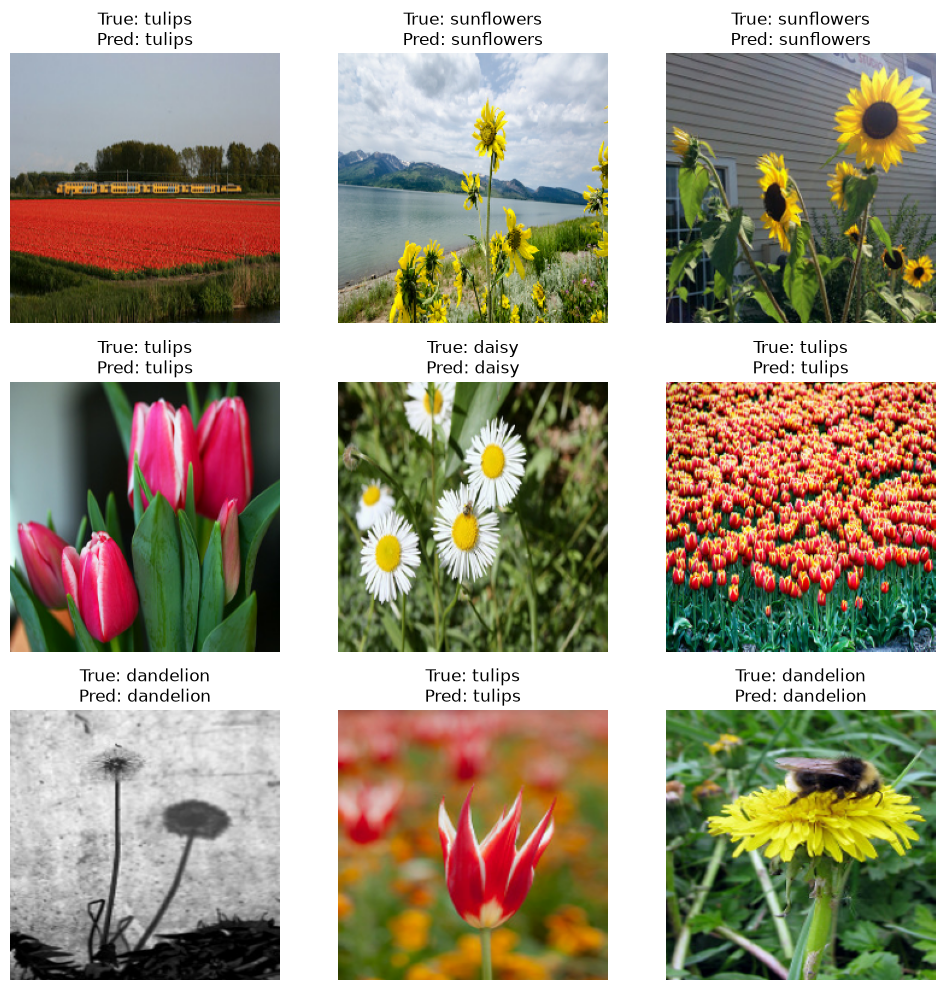

Predicted flower: tulips


In [3]:
# Import libraries
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt
import numpy as np
import os

# Step 1: Download the flower dataset
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir = tf.keras.utils.get_file(
    "flower_photos", url, untar=True
)

# Step 2: Find the correct dataset directory
classes = {"daisy", "dandelion", "roses", "sunflowers", "tulips"}

for root, dirs, files in os.walk(data_dir):
    if classes.issubset(set(dirs)):
        data_dir = root
        break

# Step 3: Load training and validation data
train_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=32
)

val_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=32
)

class_names = train_ds.class_names
print("Classes:", class_names)

# Step 4: Display sample images
images, labels = next(iter(train_ds))

plt.figure(figsize=(8, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[int(labels[i].numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Step 5: Preprocess images
train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

# Step 6: Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

# Step 7: Add classification layers
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_names), activation="softmax")
])

# Step 8: Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Step 9: Train the model
model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

# Step 10: Predict flower classes
images, labels = next(iter(val_ds))
predictions = model.predict(images)
predicted_labels = np.argmax(predictions, axis=1)

# Step 11: Display predictions
plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    # Convert preprocessed images back to displayable RGB
    img = images[i].numpy()
    img = ((img + 1) * 127.5).clip(0, 255).astype("uint8")
    plt.imshow(img)

    true_label = class_names[int(labels[i].numpy())]
    pred_label = class_names[predicted_labels[i]]

    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Step 12: Display prediction for one image
print("Predicted flower:", class_names[predicted_labels[0]])